---
title: "A Vocabulary for Task Abstraction"
subtitle: "DS 2023 | Communicating with Data"
---

## Overview

Throughout this course, we have seen that every visualization is produced by two kinds of work.

- **First**, you shape and summarize the source data until it has the form the chart needs.

- **Second**, you map the data onto on the visual elements of a canvas — marks, scales, facets, labels, etc.

These two kinds of work have their own **vocabularies**.

- The **data mutation words** describe what you do to a table.

- The **visual composition words** describe what you do to a figure.

These two vocabularies help you **plan your code** before you write it.

- They also map directly onto the **operations level** of the Visualization Task Hierarchy.
- Each verb is a concrete form of the abstract "Verb + Object" pattern from Gotz and Zhou (2008).

## The Visualization Task Hierarchy

Here is a summary of the VTH process:

**1 Start at the Task level**. 

- State the central analytical question the dashboard is meant to answer.
- This scopes everything below it.
- This question should be answerable within the scope of your data.

**2 Decompose into Sub-tasks**. 

- Break the central question into the 3–5 specific questions a user must answer to reach the goal.
- Each sub-task is a logical unit of the dashboard (a panel, a view, a filter section).

**3 Operationalize each sub-task**. 

- Rephrase it as a Verb + Object using a controlled vocabulary, e.g. Amar's primitives (Correlate, Characterize Distribution, Filter, Find Extremum, etc.).
- This tells you what kind of visualization is needed, not just what data to show.

**4 Map operations to Actions**. 

- Decide what interactive moves (query, filter, zoom, plot) the user needs to perform that operation.
- These become your widget choices: sliders, dropdowns, linked charts.

**5 Ask: what trails does this dashboard support?** 

- A trail is a sequence of actions leading to a discovery.
- If you can't trace a plausible path from the Task question to an insight using your dashboard's controls, something is missing.

**The practical payoff:** instead of asking "what chart should I use?", you're asking "what question does this panel answer, and what action does the user take here?" That keeps every design decision anchored to the user's analytical intent rather than aesthetics.

## Our own vocabulary

:::{table} The two verb domains
| Domain | Question it answers | Typical tool |
|---|---|---|
| **Data Mutation** | What does the table need to look like? | pandas |
| **Visual Composition** | What does the figure need to show? | Seaborn / Matplotlib |
:::

A useful rule of thumb:

- If you are touching a DataFrame, you are in the **data mutation** domain.
- If you are touching an `Axes` or calling a Seaborn function, you are in the **visual composition** domain.

Many visualization bugs come from mixing the two — trying to fix a chart problem with a data fix, or the reverse.
Naming the domain first points you at the right tool.

## Data Mutation Verbs

These verbs operate on a DataFrame.
They produce another DataFrame (or a scalar summary).
They do not care about colors, axes, or marks.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

The examples in this section use the `penguins` dataset from Seaborn.
It records body measurements for $344$ penguins across three species
(`Adelie`, `Chinstrap`, `Gentoo`) on three Antarctic islands.
Columns include `species`, `island`, `bill_length_mm`, `bill_depth_mm`,
`flipper_length_mm`, `body_mass_g`, and `sex`.

In [3]:
penguins = sns.load_dataset('penguins')
penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


### Define / Declare

**Establish an attribute and its measurement scale.**

Every column has a dtype that encodes its scale of measurement:
`float64` for quantitative, `category` for nominal or ordinal, `datetime64` for temporal.
Pandas infers dtypes on load, but sometimes you need to declare them explicitly.

The `astype()` method is the most direct way to do this.

In [4]:
# Declare 'species' as a categorical (nominal) variable
penguins_typed = penguins.copy()
penguins_typed['species'] = penguins_typed['species'].astype('category')
print(penguins_typed['species'].dtype)

category


### Derive / Mutate

**Compute a new column from existing ones.**

Use `df.assign()` to add derived columns without modifying the original DataFrame.
The new column is a function of existing columns.

In [5]:
# Derive bill_ratio: the ratio of bill length to bill depth
penguins = penguins.assign(bill_ratio=penguins['bill_length_mm'] / penguins['bill_depth_mm'])
penguins[['species', 'bill_length_mm', 'bill_depth_mm', 'bill_ratio']].head()

,species,bill_length_mm,bill_depth_mm,bill_ratio
0,Adelie,39.1,18.7,2.090909
1,Adelie,39.5,17.4,2.270115
2,Adelie,40.3,18.0,2.238889
3,Adelie,NaN,NaN,NaN
4,Adelie,36.7,19.3,1.901554


### Filter / Slice

**Restrict rows to those satisfying a predicate.**

Boolean indexing selects rows where the condition is `True`.
The result is a smaller DataFrame with the same columns.

In [6]:
# Keep only Gentoo penguins
gentoo = penguins[penguins['species'] == 'Gentoo']
print(f'{len(gentoo)} rows after filtering to Gentoo')
gentoo.head()

124 rows after filtering to Gentoo


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,bill_ratio
220,Gentoo,Biscoe,46.1,13.2,211.0,4500.0,Female,3.492424
221,Gentoo,Biscoe,50.0,16.3,230.0,5700.0,Male,3.067485
222,Gentoo,Biscoe,48.7,14.1,210.0,4450.0,Female,3.453901
223,Gentoo,Biscoe,50.0,15.2,218.0,5700.0,Male,3.289474
224,Gentoo,Biscoe,47.6,14.5,215.0,5400.0,Male,3.282759


### Sort

**Reorder rows by one or more attribute values.**

Use `sort_values()`.
Pass `ascending=False` to sort from largest to smallest.

In [7]:
# Sort penguins by body_mass_g, heaviest first
penguins_sorted = penguins.sort_values('body_mass_g', ascending=False)
penguins_sorted[['species', 'island', 'body_mass_g']].head()

,species,island,body_mass_g
237,Gentoo,Biscoe,6300.0
253,Gentoo,Biscoe,6050.0
297,Gentoo,Biscoe,6000.0
337,Gentoo,Biscoe,6000.0
331,Gentoo,Biscoe,5950.0


### Project

**Select a subset of columns.**

Projection reduces the table to only the attributes you need.
Pass a list of column names to `df[[...]]`.

In [8]:
# Project down to three columns
penguins[['species', 'flipper_length_mm', 'body_mass_g']].head()

,species,flipper_length_mm,body_mass_g
0,Adelie,181.0,3750.0
1,Adelie,186.0,3800.0
2,Adelie,195.0,3250.0
3,Adelie,NaN,NaN
4,Adelie,193.0,3450.0


### Aggregate / Roll-Up

**Collapse rows into summary statistics.**

`groupby().agg()` groups rows by one or more columns and applies an aggregation
function — `mean`, `median`, `count`, `sum`, or a custom function — to each group.

In [9]:
# Mean body mass and flipper length by species
penguins.groupby('species')[['body_mass_g', 'flipper_length_mm']].agg('mean').round(1)

,body_mass_g,flipper_length_mm
species,,
Adelie,3700.7,190.0
Chinstrap,3733.1,195.8
Gentoo,5076.0,217.2


### Pivot / Reshape

**Change the layout of the table.**

`pivot_table()` rotates one column's values into new column headers.
This produces "wide" data, where each category gets its own column.
Wide data is convenient for certain chart types and for side-by-side comparisons.

In [10]:
# Pivot: rows = island, columns = species, values = mean body_mass_g
penguins.pivot_table(
    index='island',
    columns='species',
    values='body_mass_g',
    aggfunc='mean'
).round(0)

species,Adelie,Chinstrap,Gentoo
island,,,
Biscoe,3710.0,NaN,5076.0
Dream,3688.0,3733.0,NaN
Torgersen,3706.0,NaN,NaN


### Blend / Join

**Merge two datasets on a shared key.**

`pd.merge()` combines two DataFrames by matching rows on one or more key columns.
This is the "join" from relational algebra, brought into pandas.

In [11]:
# Build a small lookup table mapping species to a common name
species_info = pd.DataFrame({
    'species':     ['Adelie', 'Chinstrap', 'Gentoo'],
    'common_name': ['Adelie penguin', 'Chinstrap penguin', 'Gentoo penguin'],
    'clade':       ['Pygoscelis', 'Pygoscelis', 'Pygoscelis']
})

# Merge the lookup into the penguins DataFrame
penguins_merged = pd.merge(penguins, species_info, on='species')
penguins_merged[['species', 'common_name', 'body_mass_g']].head()

,species,common_name,body_mass_g
0,Adelie,Adelie penguin,3750.0
1,Adelie,Adelie penguin,3800.0
2,Adelie,Adelie penguin,3250.0
3,Adelie,Adelie penguin,NaN
4,Adelie,Adelie penguin,3450.0


## Visual Composition Verbs

These verbs operate on a figure or axes object.
They assume the data is already in the correct shape.
They do not touch the DataFrame.

### Bind / Map

**Assign a data attribute to a visual channel.**

A visual channel is any perceptual dimension that can carry information:
position ($x$, $y$), color, size, shape, opacity.
In Seaborn, bindings are declared as keyword arguments: `x=`, `y=`, `hue=`, `size=`, `style=`.

The cell below binds `bill_length_mm` to the $x$-axis, `body_mass_g` to the $y$-axis,
and `species` to color (`hue`).

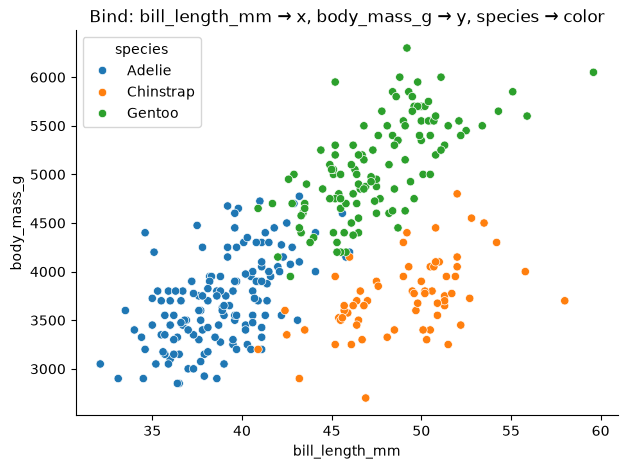

In [12]:
fig, ax = plt.subplots(figsize=(7, 5))

sns.scatterplot(
    data=penguins.dropna(),
    x='bill_length_mm',
    y='body_mass_g',
    hue='species',
    ax=ax
)

ax.set_title('Bind: bill_length_mm → x, body_mass_g → y, species → color')
sns.despine()
plt.show()

### Scale

**Define the transformation between the data domain and the visual range.**

By default, Matplotlib uses a linear scale.
A log scale compresses large ranges; a categorical scale spaces discrete values evenly.
Color scales (palettes) map a data range onto a sequence of hues or shades.

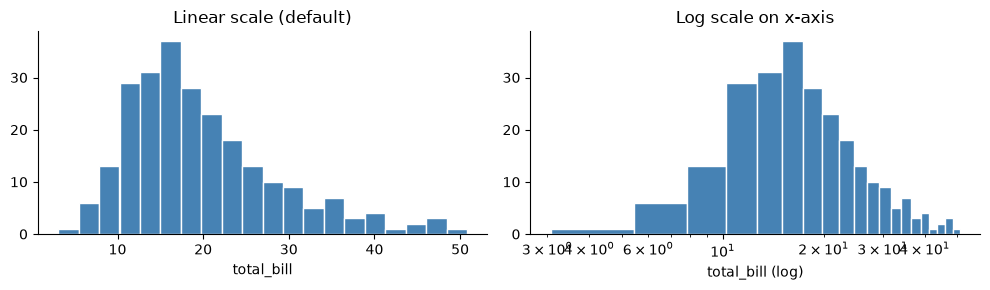

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))

# Linear scale (default)
tips = sns.load_dataset('tips')
axes[0].hist(tips['total_bill'], bins=20, color='steelblue', edgecolor='white')
axes[0].set_title('Linear scale (default)')
axes[0].set_xlabel('total_bill')

# Log scale on x-axis
axes[1].hist(tips['total_bill'], bins=20, color='steelblue', edgecolor='white')
axes[1].set_xscale('log')
axes[1].set_title('Log scale on x-axis')
axes[1].set_xlabel('total_bill (log)')

sns.despine()
plt.tight_layout()
plt.show()

### Render / Draw

**Instantiate a geometric mark.**

A mark is the basic visual unit: a point, a bar, a line, an area.
Choosing a mark is choosing how each row of data appears on the canvas.
Seaborn's named plot functions (`scatterplot`, `barplot`, `lineplot`) each render a different mark type.

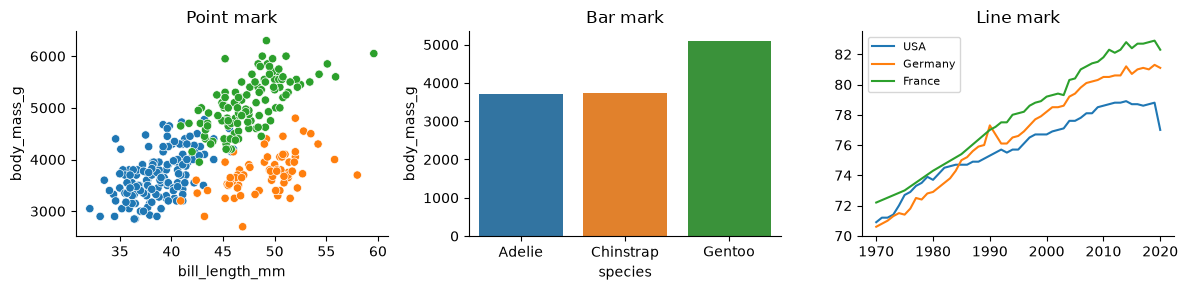

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))

penguins_clean = penguins.dropna()
species_mass = penguins_clean.groupby('species')['body_mass_g'].mean().reset_index()

# Point mark
sns.scatterplot(data=penguins_clean, x='bill_length_mm', y='body_mass_g',
                hue='species', ax=axes[0], legend=False)
axes[0].set_title('Point mark')

# Bar mark
sns.barplot(data=species_mass, x='species', y='body_mass_g',
            hue='species', ax=axes[1], legend=False)
axes[1].set_title('Bar mark')

# Line mark
healthexp = sns.load_dataset('healthexp')
for country in ['USA', 'Germany', 'France']:
    subset = healthexp[healthexp['Country'] == country]
    axes[2].plot(subset['Year'], subset['Life_Expectancy'], label=country)
axes[2].set_title('Line mark')
axes[2].legend(fontsize=8)

sns.despine()
plt.tight_layout()
plt.show()

### Transform (Statistical)

**Compute a visualization-specific summary on the fly.**

Some chart functions bin continuous values, smooth a curve, or compute a confidence interval
as part of the rendering step — not as a separate data step.
This is a statistical transform built into the visual layer.

`sns.histplot()` bins raw values into counts.
`sns.regplot()` fits and draws a regression line with a confidence band.

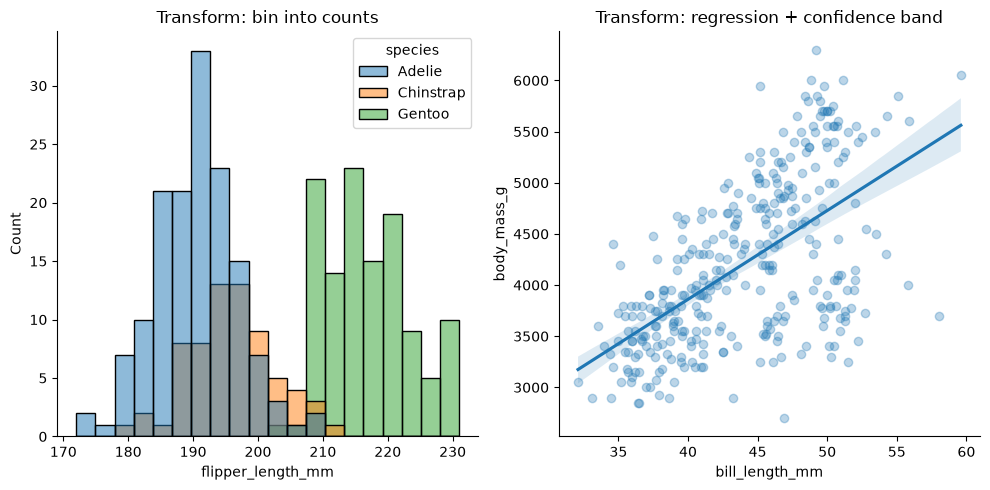

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# Statistical transform: binning (histplot)
sns.histplot(data=penguins_clean, x='flipper_length_mm', hue='species',
             bins=20, ax=axes[0])
axes[0].set_title('Transform: bin into counts')

# Statistical transform: regression + CI (regplot)
sns.regplot(data=penguins_clean, x='bill_length_mm', y='body_mass_g',
            scatter_kws={'alpha': 0.3}, ax=axes[1])
axes[1].set_title('Transform: regression + confidence band')

sns.despine()
plt.tight_layout()
plt.show()

### Facet

**Split the canvas into sub-plots by a categorical attribute.**

Faceting creates one panel per category value.
It lets you compare the same chart across groups without overlapping marks.
In Seaborn, the `col=` or `row=` arguments to `sns.relplot()` and `sns.displot()` handle faceting.

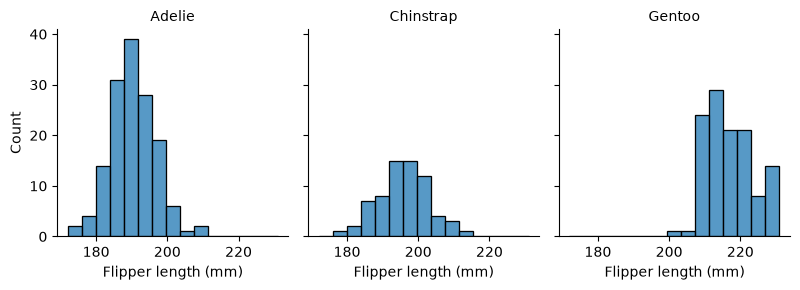

In [22]:
g = sns.displot(
    data=penguins_clean,
    x='flipper_length_mm',
    col='species',
    bins=15,
    height=3,
    aspect=0.9
)
g.set_titles(col_template='{col_name}')
g.set_xlabels('Flipper length (mm)')
plt.show()

### Layer

**Superimpose multiple geometric marks on the same axes.**

Layering adds information density without adding panels.
In Matplotlib, you layer by making multiple plot calls on the same `ax` object.

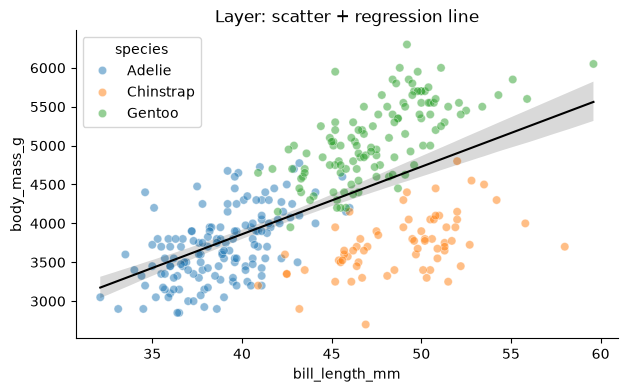

In [23]:
fig, ax = plt.subplots(figsize=(7, 4))

# Layer 1: scatter points
sns.scatterplot(data=penguins_clean, x='bill_length_mm', y='body_mass_g',
                hue='species', alpha=0.5, ax=ax)

# Layer 2: regression line for all species combined
sns.regplot(data=penguins_clean, x='bill_length_mm', y='body_mass_g',
            scatter=False, color='black', line_kws={'linewidth': 1.5}, ax=ax)

ax.set_title('Layer: scatter + regression line')
sns.despine()
plt.show()

### Annotate

**Add non-data marks: titles, labels, reference lines, text.**

Annotation does not encode new data — it explains or contextualizes what is already shown.
Use `ax.set_title()`, `ax.set_xlabel()`, `ax.axhline()`, `ax.axvline()`, and `ax.text()`.

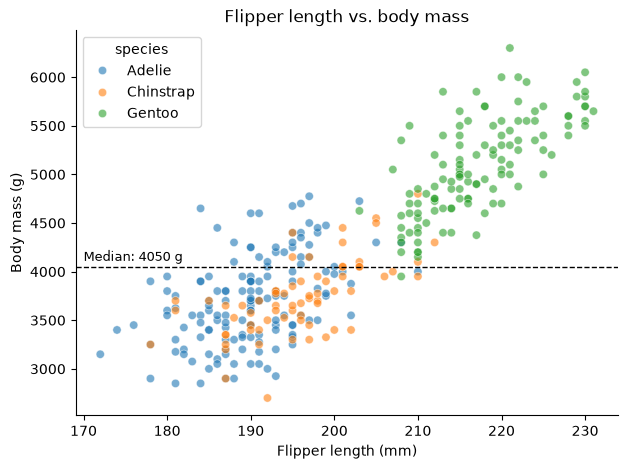

In [25]:
fig, ax = plt.subplots(figsize=(7, 5))

sns.scatterplot(data=penguins_clean, x='flipper_length_mm', y='body_mass_g',
                hue='species', alpha=0.6, ax=ax)

# Annotate: reference line at the overall median body mass
median_mass = penguins_clean['body_mass_g'].median()
ax.axhline(median_mass, color='black', linewidth=1, linestyle='--')
ax.text(170, median_mass + 60, f'Median: {median_mass:.0f} g', fontsize=9)

ax.set_title('Flipper length vs. body mass')
ax.set_xlabel('Flipper length (mm)')
ax.set_ylabel('Body mass (g)')
sns.despine()
plt.show()

## Worked Example: Verb Chain from Question to Plot

Let's walk through a complete verb chain — from a plain analytical question
to a finished visualization — naming each verb as we apply it.

### The Question

**Do heavier penguins have proportionally longer bills, and does this differ by species?**

### The Verb Chain

**Data mutation steps:**

1. **Filter** — drop rows with missing values so every downstream step has clean input.
2. **Derive** — compute `bill_ratio` (bill length ÷ bill depth) as the "proportionality" measure.
3. **Aggregate** — compute the mean `bill_ratio` and mean `body_mass_g` per species,
   to add a per-species summary layer.

**Visual composition steps:**

4. **Bind** — map `body_mass_g` → $x$, `bill_ratio` → $y$, `species` → color.
5. **Render** — draw a scatter mark for the individual penguins.
6. **Layer** — superimpose per-species mean points as larger markers.
7. **Annotate** — add a title and axis labels.

Let's execute each step.

In [26]:
# Step 1 — Filter: drop rows with any missing value
df = sns.load_dataset('penguins').dropna()
print(f'{len(df)} rows after filtering')

# Step 2 — Derive: compute bill_ratio
df = df.assign(bill_ratio=df['bill_length_mm'] / df['bill_depth_mm'])

# Step 3 — Aggregate: per-species means
species_means = (
    df.groupby('species')[['body_mass_g', 'bill_ratio']]
    .mean()
    .reset_index()
)
species_means

333 rows after filtering


,species,body_mass_g,bill_ratio
0,Adelie,3706.164384,2.121478
1,Chinstrap,3733.088235,2.653756
2,Gentoo,5092.436975,3.176602


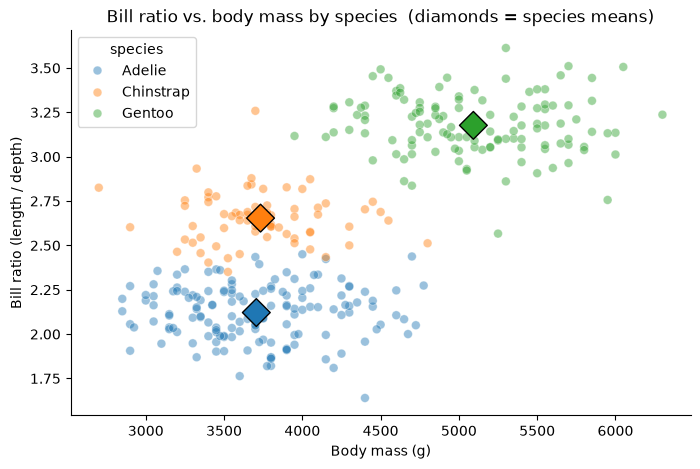

In [27]:
fig, ax = plt.subplots(figsize=(8, 5))

# Step 4 + 5 — Bind + Render: scatter of individual penguins
sns.scatterplot(
    data=df,
    x='body_mass_g',
    y='bill_ratio',
    hue='species',
    alpha=0.45,
    s=40,
    ax=ax
)

# Step 6 — Layer: per-species mean points
sns.scatterplot(
    data=species_means,
    x='body_mass_g',
    y='bill_ratio',
    hue='species',
    s=200,
    marker='D',
    edgecolor='black',
    linewidth=1,
    legend=False,
    ax=ax
)

# Step 7 — Annotate
ax.set_title('Bill ratio vs. body mass by species  (diamonds = species means)')
ax.set_xlabel('Body mass (g)')
ax.set_ylabel('Bill ratio (length / depth)')
sns.despine()
plt.show()

## Summary

:::{table} Visualization action verbs and their pandas / Seaborn counterparts
| Domain | Verb | What it does | Pandas / Seaborn |
|---|---|---|---|
| Data Mutation | Define / Declare | Set a column's dtype and measurement scale | `astype()` |
| Data Mutation | Derive / Mutate | Compute a new column from existing ones | `assign()` |
| Data Mutation | Filter / Slice | Keep rows that satisfy a predicate | `df[condition]`, `.query()` |
| Data Mutation | Sort | Reorder rows by attribute value | `sort_values()` |
| Data Mutation | Project | Select a subset of columns | `df[['a', 'b']]` |
| Data Mutation | Aggregate / Roll-Up | Collapse rows into summaries | `groupby().agg()` |
| Data Mutation | Pivot / Reshape | Change the table layout | `pivot_table()`, `melt()` |
| Data Mutation | Blend / Join | Merge datasets on a shared key | `pd.merge()` |
| Visual Composition | Bind / Map | Assign a data attribute to a visual channel | `x=`, `y=`, `hue=`, `size=` |
| Visual Composition | Scale | Set the data-to-visual-range transformation | `set_xscale()`, color palettes |
| Visual Composition | Render / Draw | Instantiate a geometric mark | `sns.scatterplot()`, `barplot()`, `lineplot()` |
| Visual Composition | Transform (Statistical) | Compute summaries inside the visual layer | `sns.histplot()`, `sns.regplot()` |
| Visual Composition | Facet | Split into sub-plots by category | `col=`, `row=`, `FacetGrid` |
| Visual Composition | Layer | Superimpose marks on the same axes | Multiple calls on the same `ax` |
| Visual Composition | Annotate | Add titles, labels, reference marks | `set_title()`, `axhline()`, `text()` |
:::

:::{note}
When you get stuck on a visualization problem, name the domain first.
Is the problem in the data (wrong shape, missing column, wrong aggregation) or in the figure (wrong channel, missing annotation, bad scale)?
Naming the domain tells you which tool to reach for.
:::